# AlexNet

AlexNet представили Алекс Крижевский, Илья Суцкевер и Джеффри Хинтон в 2012 году. Сеть с пятью свёрточными слоями обучали на ImageNet. Вариант этой модели победил в соревновании по распознаванию изображений того же года. [Оригинальная статья](https://papers.nips.cc/paper_files/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html).

В этом ноутбуке мы адаптируем AlexNet для CIFAR-10. Изображения здесь имеют размер 32×32 вместо 224×224, поэтому первую свёртку меняем с 11×11 и шага 4 на 3×3 и шаг 1. Иначе уже в начале сети карта признаков стала бы слишком маленькой.

К слоям pooling добавляем `padding=1`, чтобы карты на маленьком входе не сжимались слишком резко. Из-за нового размера карт пересчитываем число входов первого линейного слоя. Полносвязную часть тоже делаем компактнее: вместо двух слоёв по 4096 нейронов используем слои на 512 и 256. Выходной слой меняем с 1000 на 10 чисел - по числу классов CIFAR-10.

Ещё убираем группировку свёрток (`groups=2`), так как в оригинале она была связана с распределением вычислений между двумя GPU, а здесь в ней нет необходимости.

Ниже показана схема нашей версии AlexNet.

<img src="images/alexnet.svg" alt="Схема AlexNet" height="700">

In [ ]:
import torch.nn as nn
import torch
import pandas as pd
from typing import Callable
from torch.utils.data import TensorDataset
import sys
sys.path.append("../utils")
from data_utils import images_to_tensor, train_dataset_split, create_dataloader, calculate_mean_std, AutoAugumentationDataset, StandardizationDataset, TestImagesDataset

In [ ]:
import importlib
import data_utils
importlib.reload(data_utils)
# убрать

In [2]:
SEED = 52

torch.manual_seed(SEED)

## Работа с данными

In [3]:
X_train, y_train = images_to_tensor(
    "../data/train",
    "../data/trainLabels.csv",
)

Создаём Dataset который умеет выдавать по одному значению, он используется в DataLoader

In [4]:
ds_train = TensorDataset(X_train, y_train)

Разобъём train на train и val с помощью `train_dataset_split` из data_utils

In [5]:
ds_train, ds_val = train_dataset_split(ds_train, train_size=0.8, random_seed=SEED)

### Стандартизация и аугментация данных

После разделения данных вычислим среднее и стандартное отклонение для каждого канала только на train. Затем вычтем среднее и разделим на стандартное отклонение для train, val и test

К train перед стандартизацией применим уже готовую стратегию AutoAugmentPolicy.CIFAR10. При каждой выдаче картинки он случайно выбирает вариант из двух операций, каждая операция имеет вероятность срабатывания. стратегия включает:

- Геометрические изменения: поворот (Rotate), сдвиг вправо или влево (TranslateX), вверх или вниз (TranslateY), наклон (ShearY).

- Изменения изображения: яркость (Brightness), насыщенность цвета (Color), контраст (Contrast), резкость (Sharpness), инверсию (Invert), соляризацию (Solarize), уменьшение числа цветов (Posterize), автоматическую настройку контраста (AutoContrast) и выравнивание гистограммы (Equalize).

Замечание: Val и test проходят только стандартизацию, без аугментации.

Ниже приведены примеры аугументаций:
- 1.png с лягушкой сдвинулась вправо
- 2.png с грузовиком сдвинулась вверх
- 7.png с птицей стала темнее
- 8.png с лошадью изменились цвета и контраст

<img src="images/autoaugment_examples.png" alt="Примеры AutoAugment" width="450">

In [6]:
# считаем mean и std только по исходным картинкам из train
mean, std = calculate_mean_std(ds_train)

ds_train_aug = AutoAugumentationDataset(ds_train)
ds_train_ready = StandardizationDataset(ds_train_aug, mean, std)
ds_val_ready = StandardizationDataset(ds_val, mean, std)

In [9]:
BATCH_SIZE = 512

Создаём DataLoader для train и val, которые будут выдавать наши пары (картинка, класс) батчами  при обучении

In [10]:
dl_train = create_dataloader(ds_train_ready, BATCH_SIZE, shuffle=True, random_seed=SEED)
dl_val = create_dataloader(ds_val_ready, BATCH_SIZE, shuffle=False, random_seed=SEED)

## Создание класса AlexNet

In [11]:
class AlexNet(nn.Module):
    """Упрощённая адаптация AlexNet для изображений CIFAR-10 размером 32x32."""

    def __init__(
        self,
        in_channels: int = 3,
        output_size: int = 10,
        image_size: tuple[int, int] = (32, 32)
    ):

        super().__init__()

        modules = []
        conv_layers = [96, 256, 384, 384, 256]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных блоков (смотреть схему)

            # свёртка
            if i == 1:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=5,
                    stride=1,
                    padding=2,
                    ))
            else:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=3,
                    stride=1,
                    padding=1,
                    ))
            in_ = conv_layers[i]

            modules.append(nn.ReLU()) # слой активации после какждой свёртки

            if i in [0, 1]:
                modules.append(nn.LocalResponseNorm(size=5)) # значение size=5 взято из оригинальной версии

            if i in [0, 1, 4]: # в блоках 1, 2, 5 есть maxpool
                modules.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))

        #вычиляем на искусственном примере размер картинки, который получился после всех свёрток
        with torch.no_grad():
            sample = torch.zeros(1, in_channels, *image_size)
            in_features = nn.Sequential(*modules)(sample).flatten(1).shape[1]

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())
        # после выпрямления получаем вектор из 4096 чисел

        # 1 линейный слой на 512 нейронов
        modules.append(nn.Linear(in_features, 512))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # 2 линейный слой на 256 нейронов
        modules.append(nn.Linear(512, 256))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(256, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [12]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Устройство: {DEVICE}")

Устройство: mps


In [13]:
alexnet = AlexNet(3, 10).to(DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(alexnet.parameters(), lr=3e-4)

In [14]:
import sys
sys.path.append("../utils")
from train_utils import train, test

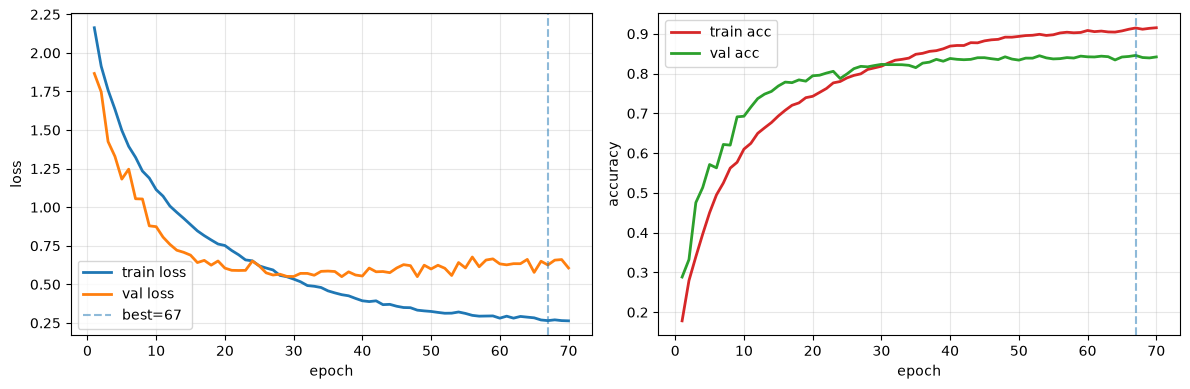

In [ ]:
train(alexnet, optimizer, loss_func, dl_train, dl_val, "models/alexnet.pth", DEVICE, EPOCH_COUNT=150, patience=25)

## Тестирование

Загрузим веса лучшей эпохи. Тестовые картинки будем читать батчами в порядке `sampleSubmission.csv`, затем сохраним предсказания в файл submission.

In [ ]:
alexnet_best = AlexNet(3, 10, (32, 32)).to(DEVICE)
alexnet_best.load_state_dict(torch.load('models/alexnet.pth', map_location=DEVICE))
alexnet_best.eval()

In [ ]:
ds_test = TestImagesDataset(
    "../data/test",
    "../data/sampleSubmission.csv",
)

In [ ]:
ds_test_ready = StandardizationDataset(ds_test, mean, std)
dl_test = create_dataloader(ds_test_ready, batch_size=BATCH_SIZE, shuffle=False)
class_names = sorted(pd.read_csv("../data/trainLabels.csv")["label"].unique())

In [ ]:
submission = test(
    alexnet_best,
    dl_test,
    class_names,
    "../data/sampleSubmission.csv",
    "alexnet_submission.csv",
    DEVICE,
)

## Итог


В ходе работы была реализована и обучена адаптированная архитектура **AlexNet** для классификации изображений датасета CIFAR-10. До добавления аугментации и стандартизации максимальная точность на валидационной выборке составила **80,06 %** и была достигнута на 109-й эпохе.

Полученный результат свидетельствует об эффективности модели при решении задачи классификации цветных изображений. AlexNet, предложенная в 2012 году, стала важным этапом развития глубокого обучения благодаря использованию нескольких свёрточных слоёв, позволяющих извлекать признаки различной сложности. Несмотря на необходимость адаптации исходной архитектуры под небольшой размер изображений CIFAR-10, модель показала хорошие результаты, продемонстрировав способность распознавать объекты из десяти классов.
